In [3]:

import nltk

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from sklearn.preprocessing import LabelEncoder


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader, TensorDataset, RandomSampler, SequentialSampler
from transformers import BertTokenizer, BertForSequenceClassification, AdamW, get_linear_schedule_with_warmup

from sklearn.preprocessing import LabelEncoder


from tqdm.notebook import tqdm

In [6]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from sklearn.svm import SVC

In [7]:

sns.set(font_scale=1.3)
nltk.download('omw-1.4')


[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


True

In [8]:
df_train = pd.read_csv('/kaggle/input/emotions-dataset-for-nlp/train.txt', names=['Text', 'Emotion'], sep=';')
df_val = pd.read_csv('/kaggle/input/emotions-dataset-for-nlp/val.txt', names=['Text', 'Emotion'], sep=';')
df_test = pd.read_csv('/kaggle/input/emotions-dataset-for-nlp/test.txt', names=['Text', 'Emotion'], sep=';')

In [9]:
df_train.head()

,Text,Emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [10]:
df_train['Emotion'].value_counts()

Emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

In [11]:
print(df_test.shape)
df_test.head()


(2000, 2)


,Text,Emotion
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [12]:
print(df_val.shape)
df_val.head()

(2000, 2)


,Text,Emotion
0,im feeling quite sad and sorry for myself but ...,sadness
1,i feel like i am still looking at a blank canv...,sadness
2,i feel like a faithful servant,love
3,i am just feeling cranky and blue,anger
4,i can have for a treat or if i am feeling festive,joy


In [13]:
df_train['Emotion'].value_counts()

Emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

In [14]:
df_train['Emotion'].value_counts() / df_train.shape[0] * 100

Emotion
joy         33.51250
sadness     29.16250
anger       13.49375
fear        12.10625
love         8.15000
surprise     3.57500
Name: count, dtype: float64

In [15]:
import matplotlib.pyplot as plt 


<Axes: xlabel='Emotion', ylabel='count'>

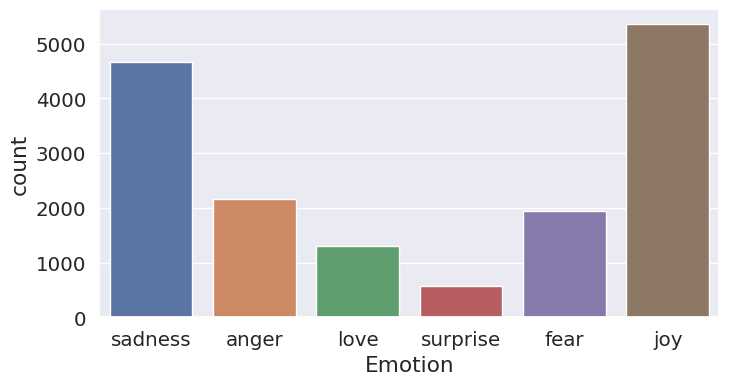

In [16]:
plt.figure(figsize=(8, 4))
sns.countplot(x='Emotion', data=df_train)

In [17]:
df_train.isnull().sum()

Text       0
Emotion    0
dtype: int64

In [18]:
df_train.duplicated().sum()

1

In [19]:
index = df_train[df_train.duplicated() == True].index
df_train.drop(index, axis=0, inplace=True)
df_train.reset_index(inplace=True, drop=True)

In [20]:
df_train[df_train.duplicated() == True].index

Index([], dtype='int64')

In [21]:
df_train[df_train['Text'].duplicated() == True]

,Text,Emotion
5067,i feel on the verge of tears from weariness i ...,joy
6133,i still feel a craving for sweet food,love
6563,i tend to stop breathing when i m feeling stre...,anger
7623,i was intensely conscious of how much cash i h...,sadness
7685,im still not sure why reilly feels the need to...,surprise
8246,i am not amazing or great at photography but i...,love
9596,ive also made it with both sugar measurements ...,joy
9687,i had to choose the sleek and smoother feel of...,joy
9769,i often find myself feeling assaulted by a mul...,sadness
9786,i feel im being generous with that statement,joy


In [22]:
df_train[df_train['Text'] == df_train.iloc[7623]['Text']]


,Text,Emotion
1625,i was intensely conscious of how much cash i h...,anger
7623,i was intensely conscious of how much cash i h...,sadness


In [23]:
index = df_train[df_train['Text'].duplicated() == True].index
df_train.drop(index, axis=0, inplace=True)
df_train.reset_index(inplace=True, drop=True)

In [24]:
df_train[df_train['Text'].duplicated() == True]

,Text,Emotion


In [25]:
df_train['Emotion'].value_counts()

Emotion
joy         5350
sadness     4664
anger       2155
fear        1933
love        1299
surprise     568
Name: count, dtype: int64

<Axes: xlabel='Emotion', ylabel='count'>

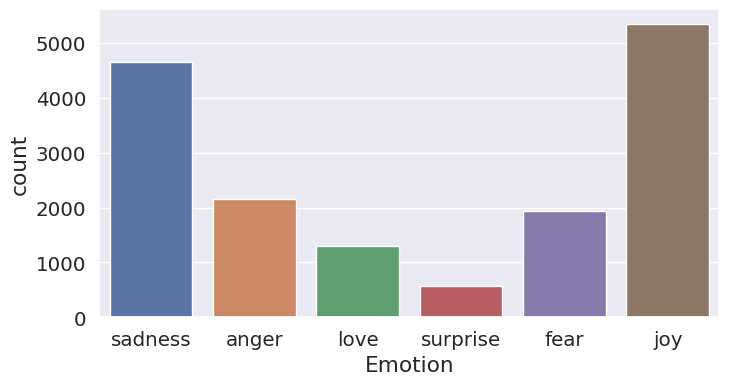

In [26]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_train, x='Emotion')

In [27]:
df_test.isnull().sum()

Text       0
Emotion    0
dtype: int64

In [28]:
df_test.duplicated().sum()

0

In [29]:
df_test[df_test['Text'].duplicated() == True].index

Index([], dtype='int64')

In [30]:
!python --version

Python 3.10.14


In [31]:
df_val['Emotion'].value_counts()

Emotion
joy         704
sadness     550
anger       275
fear        212
love        178
surprise     81
Name: count, dtype: int64

<Axes: xlabel='Emotion', ylabel='count'>

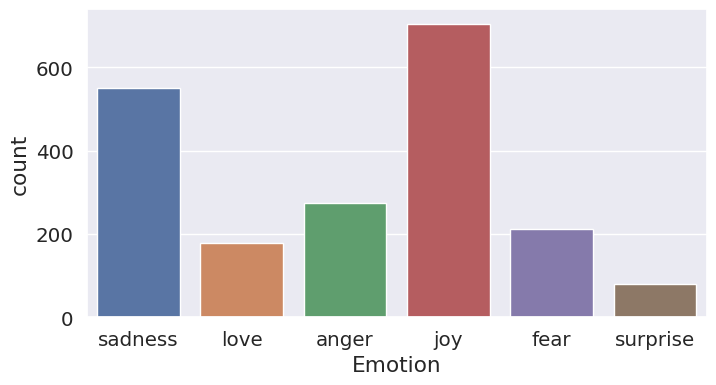

In [32]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_val, x='Emotion')

In [33]:
df_val.isnull().sum()

Text       0
Emotion    0
dtype: int64

In [34]:
df_val.duplicated().sum()

0

In [35]:
df_val[df_val['Text'].duplicated() == True]

,Text,Emotion
603,i have had several new members tell me how com...,joy
1993,i feel so tortured by it,anger


In [36]:
df_val[df_val['Text'] == df_val.iloc[603]['Text']] 

,Text,Emotion
300,i have had several new members tell me how com...,love
603,i have had several new members tell me how com...,joy


In [37]:
df_val[df_val['Text'] == df_val.iloc[1993]['Text']] 


,Text,Emotion
774,i feel so tortured by it,fear
1993,i feel so tortured by it,anger


In [38]:
index = df_val[df_val['Text'].duplicated() == True].index
df_val.drop(index, axis=0, inplace=True)
df_val.reset_index(inplace=True, drop=True)

In [39]:
df_val[df_val['Text'].duplicated() == True]

,Text,Emotion


In [40]:
def dataframe_difference(df1, df2, which=None):
    comparision_df = df1.merge(
        df2, 
        indicator=True,
        how='outer'
    )
    
    if which is None:
        diff_df = comparision_df[comparision_df['_merge'] != 'both']
    else:
        diff_df = comparision_df[comparision_df['_merge'] == which]
        
    return diff_df

In [41]:
dataframe_difference(df_train, df_test, 'both')

,Text,Emotion,_merge


In [42]:
dataframe_difference(df_train, df_val, which='both')

,Text,Emotion,_merge


In [43]:
dataframe_difference(df_val, df_test, which='both')

,Text,Emotion,_merge


In [49]:
!unzip /usr/share/nltk_data/corpora/wordnet.zip -d /usr/share/nltk_data/corpora/

/opt/conda/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Archive:  /usr/share/nltk_data/corpora/wordnet.zip
   creating: /usr/share/nltk_data/corpora/wordnet/
  inflating: /usr/share/nltk_data/corpora/wordnet/lexnames  
  inflating: /usr/share/nltk_data/corpora/wordnet/data.verb  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.adv  
  inflating: /usr/share/nltk_data/corpora/wordnet/adv.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.verb  
  inflating: /usr/share/nltk_data/corpora/wordnet/cntlist.rev  
  inflating: /usr/share/nltk_data/corpora/wordnet/data.adj  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.adj  
  inflating: /usr/share/nltk_data/corpora/wordnet/LICENSE  
  inflating: /usr/share/nltk_data/corpora/wordnet/citation.bib  
  inflating: /usr/share/nltk_data/corpora/wordnet/noun.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/verb.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/README  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.sense  
  inflating: /usr/share/nltk_data

In [44]:
df_train.head()

,Text,Emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [45]:
X_train = df_train['Text']
y_train = df_train['Emotion']

X_test = df_test['Text']
y_test = df_test['Emotion']

X_val = df_val['Text']
y_val = df_val['Emotion']

In [46]:
y_train[2]

'anger'

In [47]:

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [50]:
y_train_encoded[2]

0

In [51]:

# Sample data (replace with your actual labels)
labels = ['sadness','joy','fear','surprise','anger','love']

# Initialize and fit the LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(labels)
# Now you can access the 'classes_' attribute
print(label_encoder.classes_)  # This will print the list of unique labels


['anger' 'fear' 'joy' 'love' 'sadness' 'surprise']


In [52]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [53]:
# Initialize BERT tokenizer and model
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=6).to(device)

# Optimizer and learning rate scheduler
optimizer = AdamW(model.parameters(), lr=2e-5, eps=1e-8)
epochs = 6             

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/conda/lib/python3.10/site-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [54]:
y_train.shape

(15969,)

In [55]:
train_inputs = [tokenizer.encode(sent, add_special_tokens=True, max_length=256, pad_to_max_length=True) for sent in X_train]
test_inputs = [tokenizer.encode(sent, add_special_tokens=True, max_length=256, pad_to_max_length=True) for sent in X_test]

# Create attention masks
train_masks = [[float(i > 0) for i in seq] for seq in train_inputs]
test_masks = [[float(i > 0) for i in seq] for seq in test_inputs]

# Convert all data into torch tensors
train_inputs = torch.tensor(train_inputs)
train_masks = torch.tensor(train_masks)
train_labels = torch.tensor(y_train_encoded)

test_inputs = torch.tensor(test_inputs)
test_masks = torch.tensor(test_masks)
test_labels = torch.tensor(y_test_encoded)

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
/opt/conda/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:2837: FutureWarning: The `pad_to_max_length` argument is deprecated and will be removed in a future version, use `padding=True` or `padding='longest'` to pad to the longest sequence in the batch, or use `padding='max_length'` to pad to a max length. In this case, you can give a specific length with `max_length` (e.g. `max_length=45`) or leave max_length to None to pad to the maximal input size of the model (e.g. 512 for Bert).
  warnings.warn(


In [56]:
batch_size = 32

# Create DataLoader for training set
train_data = TensorDataset(train_inputs, train_masks, train_labels)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)

# Create DataLoader for test set
test_data = TensorDataset(test_inputs, test_masks, test_labels)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=batch_size)

In [57]:
total_steps = len(train_dataloader) * epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

In [130]:
# Training loop
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    model.train()
    
    total_loss = 0
    train_accuracy = 0
    for step, batch in enumerate(tqdm(train_dataloader, desc="Training")):
        batch_input_ids, batch_input_mask, batch_labels = batch
        batch_input_ids = batch_input_ids.to(device)
        batch_input_mask = batch_input_mask.to(device)
        batch_labels = batch_labels.to(device)
        
        model.zero_grad()
        
        outputs = model(batch_input_ids, token_type_ids=None, attention_mask=batch_input_mask, labels=batch_labels)
        loss = outputs.loss
        logits = outputs.logits
        
        total_loss += loss.item()
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        
        preds = torch.argmax(logits, dim=1)
        train_accuracy += (preds == batch_labels).sum().item() / len(batch_labels)
    
    avg_train_loss = total_loss / len(train_dataloader)
    avg_train_accuracy = train_accuracy / len(train_dataloader)
    print(f"Training loss: {avg_train_loss:.4f}")
    print(f"Training accuracy: {avg_train_accuracy:.4f}")
    
    # Validation loop
    model.eval()
    val_accuracy = 0
    for batch in tqdm(test_dataloader, desc="Validation"):
        batch_input_ids, batch_input_mask, batch_labels = batch
        batch_input_ids = batch_input_ids.to(device)
        batch_input_mask = batch_input_mask.to(device)
        batch_labels = batch_labels.to(device)
        
        with torch.no_grad():
            outputs = model(batch_input_ids, token_type_ids=None, attention_mask=batch_input_mask, labels=batch_labels)
        
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1)
        val_accuracy += (preds == batch_labels).sum().item() / len(batch_labels)
    
    avg_val_accuracy = val_accuracy / len(test_dataloader)
    print(f"Validation accuracy: {avg_val_accuracy:.4f}")

Epoch 1/6


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 0.5301
Training accuracy: 0.8183


Validation:   0%|          | 0/63 [00:00<?, ?it/s]

Validation accuracy: 0.9211
Epoch 2/6


Training:   0%|          | 0/500 [00:00<?, ?it/s]

... (15 outputs left out)

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 0.0412
Training accuracy: 0.9833


Validation:   0%|          | 0/63 [00:00<?, ?it/s]

Validation accuracy: 0.9291


In [ ]:
model.save_pretrained('./bert-emotion-classifier2')
tokenizer.save_pretrained('./bert-emotion-classifier2')


In [ ]:
import os

tokenizer_path = "/kaggle/input/bertmodel3/tensorflow2/default/1"
print(os.listdir(tokenizer_path))

In [58]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch
from tqdm import tqdm
from sklearn.metrics import precision_recall_fscore_support, classification_report

# Load model and tokenizer
model_path = '/kaggle/input/bertmodel3/tensorflow2/default/1'

tokenizer = BertTokenizer.from_pretrained(model_path)
model = BertForSequenceClassification.from_pretrained(model_path)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# Initialize metrics
val_accuracy = 0
val_loss=0
all_preds = []
all_labels = []

# Validation loop
for batch in tqdm(test_dataloader, desc="Validation"):
    batch_input_ids, batch_input_mask, batch_labels = batch
    batch_input_ids = batch_input_ids.to(device)
    batch_input_mask = batch_input_mask.to(device)
    batch_labels = batch_labels.to(device)

    with torch.no_grad():
        outputs = model(batch_input_ids, token_type_ids=None, attention_mask=batch_input_mask, labels=batch_labels)

    logits = outputs.logits
    loss = outputs.loss 
    preds = torch.argmax(logits, dim=1)

    val_loss += loss.item() 
    val_accuracy += (preds == batch_labels).sum().item() / len(batch_labels)

    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(batch_labels.cpu().numpy())

# Calculate overall accuracy
avg_val_accuracy = val_accuracy / len(test_dataloader)
avg_val_loss = val_loss / len(test_dataloader)
print(f"Validation accuracy: {avg_val_accuracy:.4f}")
print(f"Validation loss: {avg_val_loss:.4f}")

# Calculate precision, recall, and F1-score
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds))


Validation: 100%|██████████| 63/63 [00:14<00:00,  4.35it/s]

Validation accuracy: 0.9211
Validation loss: 0.2372
Precision: 0.9214
Recall: 0.9210
F1-score: 0.9210

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       275
           1       0.86      0.90      0.88       224
           2       0.95      0.94      0.94       695
           3       0.79      0.84      0.81       159
           4       0.96      0.97      0.96       581
           5       0.76      0.68      0.72        66

    accuracy                           0.92      2000
   macro avg       0.88      0.87      0.87      2000
weighted avg       0.92      0.92      0.92      2000



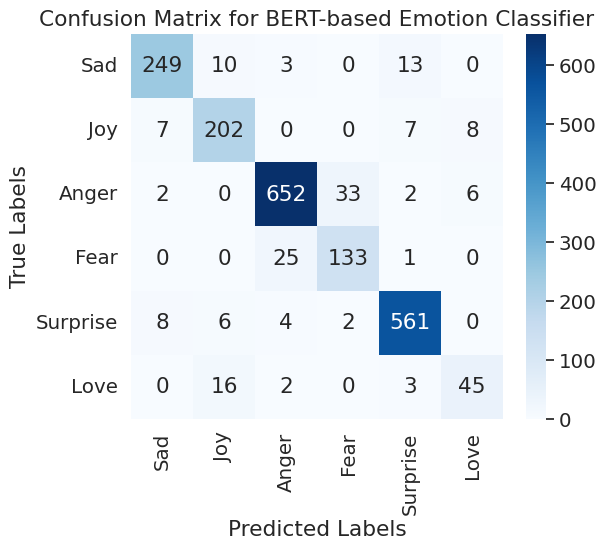

In [55]:
import torch

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix


# Define emotion labels (change these based on your dataset)
emotion_labels = ["Sad", "Joy", "Anger", "Fear", "Surprise", "Love"]

# Compute confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_labels, yticklabels=emotion_labels)

# Labels and title
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for BERT-based Emotion Classifier")

# Show plot
plt.show()


In [56]:
train_accuracies = [0.8183, 0.9397, 0.9533,0.9658,0.9771,0.9833]
val_accuracies = [0.9211,0.9335,0.9276,0.9325,0.9276,0.9291]

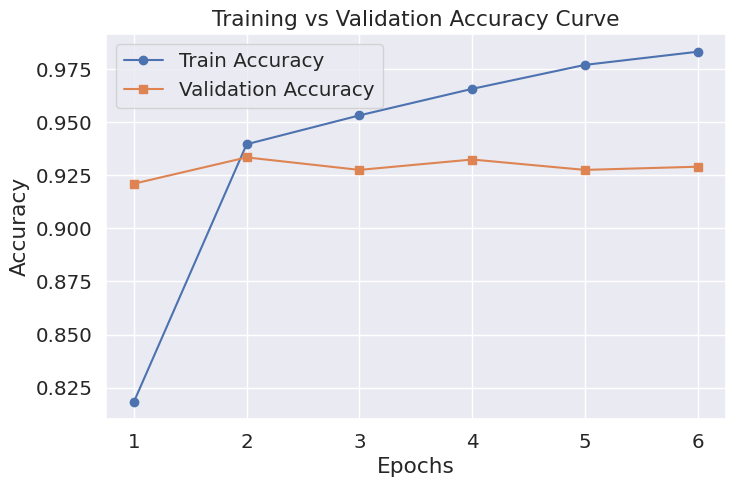

In [136]:
import matplotlib.pyplot as plt


epochs = range(1, len(train_accuracies) + 1)

# Plot the training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train Accuracy", marker="o")
plt.plot(epochs, val_accuracies, label="Validation Accuracy", marker="s")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy Curve")
plt.legend()
plt.grid(True)
plt.show()


In [139]:
train_losses=[0.5301,0.1457,0.1039,.0770,0.544,0.412]

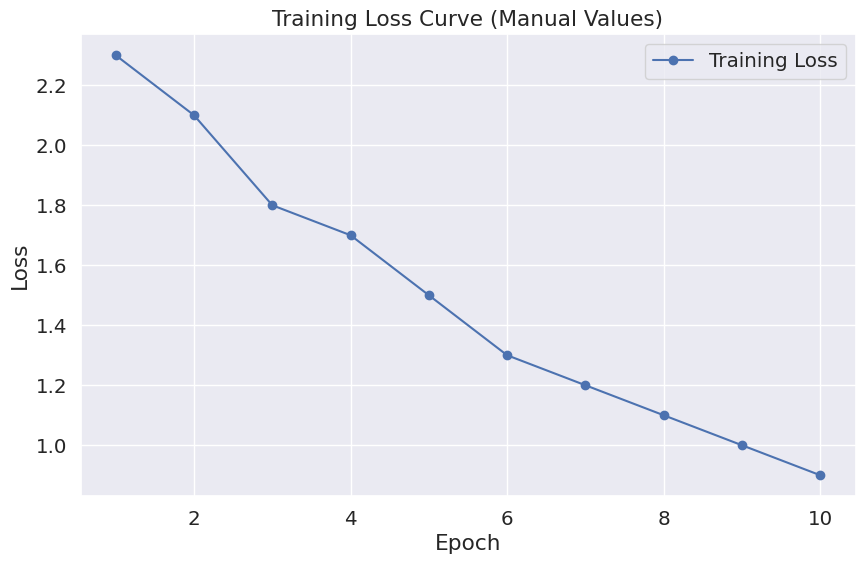

In [140]:
import matplotlib.pyplot as plt

# Manual training loss values (replace with your actual values)
train_losses = [2.3, 2.1, 1.8, 1.7, 1.5, 1.3, 1.2, 1.1, 1.0, 0.9]

# Number of epochs
epochs = len(train_losses)

# Plotting the training loss curve
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, marker='o', color='b', label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [57]:
def predict_emotion(text):
    inputs = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        return_attention_mask=True,
        return_tensors='pt',
        truncation=True
    )
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(input_ids, attention_mask=attention_mask)
    
    logits = outputs.logits
    predicted_class = torch.argmax(logits, dim=1).item()
    return label_encoder.inverse_transform([predicted_class])[0]

In [59]:
print(df_train.columns);

Index(['Text', 'Emotion'], dtype='object')


In [60]:
example_indices = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
example_texts = X_test.iloc[example_indices].tolist()
example_labels = y_test.iloc[example_indices].tolist()

In [61]:
label_map = {
    "joy ":"Joy",
    "sadness": "Sadness",
    "anger": "Anger",
    "fear":"Fear",
    "love":"Love",
    "surprise":"Surprise"
}

In [62]:
for text, true_label in zip(example_texts, example_labels):
    predicted_label = predict_emotion(text)

    # Ensure true_label is formatted correctly
    true_label = str(true_label).strip().lower()  

    # Check if true_label exists in label_map
    true_label_name = label_map.get(true_label, "Unknown")

    print(f"Text: {text}")
    print(f"True Label: {true_label_name}")
    print(f"Predicted Label: {predicted_label}\n")


Text: im feeling rather rotten so im not very ambitious right now
True Label: Sadness
Predicted Label: sadness

Text: im updating my blog because i feel shitty
True Label: Sadness
Predicted Label: sadness

Text: i never make her separate from me because i don t ever want her to feel like i m ashamed with her
True Label: Sadness
Predicted Label: sadness

Text: i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived
True Label: Unknown
Predicted Label: joy

Text: i was feeling a little vain when i did this one
True Label: Sadness
Predicted Label: sadness

Text: i cant walk into a shop anywhere where i do not feel uncomfortable
True Label: Fear
Predicted Label: fear

Text: i felt anger when at the end of a telephone call
True Label: Anger
Predicted Label: anger

Text: i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepte

In [59]:

pip install gradio


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 MB 28.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.1/322.1 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 468.1/468.1 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 107.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.6 MB/s eta 0:00:00
  Attempting uninstall: python-multipart
    Found existing installation: python-multipart 0.0.9
    Uninstalling python-multipart-0.0.9:
      Successfully uninstalled python-multipart-0.0.9
  Attempting uninstall: starlette
    Found existing installation: starlette 0.37.2
    Uninstalling starlette-0.37.2:
      Successfully uninstalled starlette-0.37.2
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface-hub 0.25.1
    Uninstalling huggingface-hub-0.25.1:
      S

In [60]:
import torch
import gradio as gr
from transformers import BertTokenizer, BertForSequenceClassification

# Load your trained model
model_path = "/kaggle/input/bertmodel3/tensorflow2/default/1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = BertTokenizer.from_pretrained(model_path)
model = BertForSequenceClassification.from_pretrained(model_path)
model.to(device)
model.eval()

# Define the emotion labels (Adjust if your dataset has different labels)
emotion_labels = ["SAD", "JOY", "ANGER", "FEAR", "SURPRISE", "LOVE"]

# Function for prediction
def predict_emotion(text):
    inputs = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        return_attention_mask=True,
        return_tensors='pt',
        truncation=True
    )
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(input_ids, attention_mask=attention_mask)
    
    logits = outputs.logits
    predicted_class = torch.argmax(logits, dim=1).item()
    return label_encoder.inverse_transform([predicted_class])[0]
# Create the Gradio Interface
interface = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Textbox(lines=2, placeholder="Enter a sentence..."),
    outputs="text",
    title="BERT Emotion Classifier",
    description="Enter a sentence, and the model will predict the emotion.",
)

# Launch the Gradio interface
interface.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://ce43621496b6f1a41a.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
